## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


In [4]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Note to selves: both 2:2 and 3:1 still need that we remove omega pts if they are already crit pts

Also note to self: needed to say CritPts[a].coords instead of CritPts[a] here for checking 4 distinct to actually work. Should we update elsewhere? check.

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

../Code/omega_pts.py:35: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'cholesky':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'cholesky' to False.
  b_eq=b,
../Code/omega_pts.py:35: OptimizeWarning: Solving system with option 'sym_pos':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'sym_pos' to False.
  b_eq=b,
/Users/celiahacker/opt/anaconda3/envs/celia/lib/python3.7/site-packages/scipy/optimize/_linprog_ip.py:117: LinAlgWarning: Ill-conditioned matrix (rcond=2.02115e-18): result may not be accurate.
  return sp.linalg.solve(M, r, sym_pos=sym_pos)
../Code/omega_pts.py:35: Op

**********
Computed 1848 points (with duplicates)
Without duplicates 60


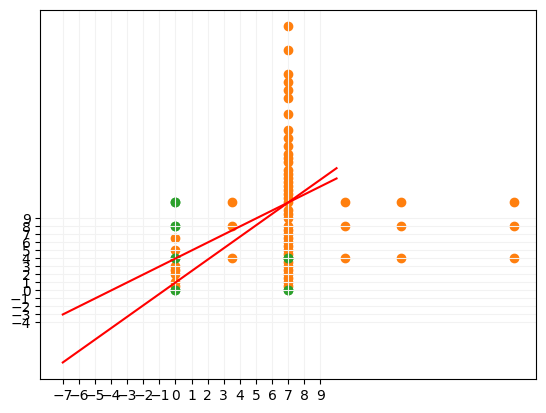

In [12]:
CritPts = ex.example_2_13()
name = "2_13"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [22]:
CritPts = ex.example_2_13()
CritPts
Omega_pts = []
length = len(CritPts)

for a in range(length):
    for b in range(a + 1, length):
        for c in range(b + 1, length):
            for d in range(c, length):
                if omega.check_4distinct([CritPts[a].coords, CritPts[b].coords, CritPts[c].coords, CritPts[d].coords]):
                    list1, list2 = omega.algo_2v2_paired([CritPts[a], CritPts[b], CritPts[c], CritPts[d]])
                    Omega_pts+=list2 

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

In [27]:
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.13_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

In [ ]:
CritPts = ex.example_2_11()
name = "2_11"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [28]:
CritPts = ex.example_2_11()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.11_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 7), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

In [ ]:
CritPts = ex.example_1()
name = "1"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [29]:
CritPts = ex.example_1()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_1_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (1, 1), (1, 1)]
beepbeep [(0, 0), (7, 0), (8, 1), (8, 1)]
beepbeep [(0, 0), (7, 0), (1, 9), (1, 9)]
beepbeep [(0, 0), (0, 8), (1, 1), (1, 1)]
beepbeep [(0, 0), (0, 8), (8, 1), (8, 1)]
beepbeep [(0, 0), (0, 8), (1, 9), (1, 9)]
beepbeep [(0, 0), (1, 1), (8, 1), (8, 1)]
beepbeep [(0, 0), (1, 1), (1, 9), (1, 9)]
beepbeep [(0, 0), (8, 1), (1, 9), (1, 9)]
beepbeep [(7, 0), (0, 8), (1, 1), (1, 1)]
beepbeep [(7, 0), (0, 8), (8, 1), (8, 1)]
beepbeep [(7, 0), (0, 8), (1, 9), (1, 9)]
beepbeep [(7, 0), (1, 1), (8, 1), (8, 1)]
beepbeep [(7, 0), (1, 1), (1, 9), (1, 9)]
beepbeep [(7, 0), (8, 1), (1, 9), (1, 9)]
beepbeep [(0, 8), (1, 1), (8, 1), (8, 1)]
beepbeep [(0, 8), (1, 1), (1, 9), (1, 9)]
beepbeep [(0, 8), (8, 1), (1, 9), (1, 9)]
beepbeep [(1, 1), (8, 1), (1, 9), (1, 9)]
**********
Computed 13 points (with duplicates)
Without duplicates 9


### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

In [ ]:
CritPts = ex.example_2()
name = "2"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)


In [30]:
CritPts = ex.example_2()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2_2v2_paired')

beepbeep [(0, 0), (4, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (4, 0), (1, 0), (1, 0)]
beepbeep [(0, 0), (4, 0), (3, 0), (3, 0)]
beepbeep [(0, 0), (4, 0), (1, 4), (1, 4)]
beepbeep [(0, 0), (0, 4), (1, 0), (1, 0)]
beepbeep [(0, 0), (0, 4), (3, 0), (3, 0)]
beepbeep [(0, 0), (0, 4), (1, 4), (1, 4)]
beepbeep [(0, 0), (1, 0), (3, 0), (3, 0)]
beepbeep [(0, 0), (1, 0), (1, 4), (1, 4)]
beepbeep [(0, 0), (3, 0), (1, 4), (1, 4)]
beepbeep [(4, 0), (0, 4), (1, 0), (1, 0)]
beepbeep [(4, 0), (0, 4), (3, 0), (3, 0)]
beepbeep [(4, 0), (0, 4), (1, 4), (1, 4)]
beepbeep [(4, 0), (1, 0), (3, 0), (3, 0)]
beepbeep [(4, 0), (1, 0), (1, 4), (1, 4)]
beepbeep [(4, 0), (3, 0), (1, 4), (1, 4)]
beepbeep [(0, 4), (1, 0), (3, 0), (3, 0)]
beepbeep [(0, 4), (1, 0), (1, 4), (1, 4)]
beepbeep [(0, 4), (3, 0), (1, 4), (1, 4)]
beepbeep [(1, 0), (3, 0), (1, 4), (1, 4)]
**********
Computed 8 points (with duplicates)
Without duplicates 6


###### remark: in this example we should not need the omega pts on the boundary of the support 

## NOtes meetin June 22
- check the code
- in example 1 we should not have (7,2) via check_omega BUT we should have (7,0), in particular the file should not be empty 

## Notes meeting June 08: 
### Todo: 
- discard $\omega$-pts that are in the closure of critical points 


## Todo: 
- print out vaalue of eta and delta when printing the omegapts and the critical points it comes from
- add something to know when it was computed in terms of line of code

## Further analysis: 
    2. Can we determine which ones are usless
    3. compute distance and see which $\Omega$-pts are interesting --> we also dont have ALL the $\Omega$-pts because we only implemented one part of the entire algo to compute the 3vs1 case and not the 2v2 cases

### IDEA: 

    omega-pts are center of symetries for bars hence they need to be in the support of the module 